# Diamond Yield Simulation

## Research question
How do random ore counts and random drops affect the number
of diamonds collected during a mining trip?

## Model assumptions
- The number of ores mined per trip follows a Poisson
  distribution with a mean of 30.
- Each ore yields 1, 2, 3 or 4 diamonds, with probabilities
  of 40%, 20%, 20% and 20%, respectively.
- Drops are independent of each other and of the ore count.
- These are illustrative assumptions, not a validated
  model of actual gameplay.

## Method
Simulate 1,000 mining trips using NumPy. Summarise the
resulting yields and compare the simulated mean with
the theoretical mean of 66 diamonds per trip.

Number of simulated trips: 1,000
Theoretical mean yield: 66.00 diamonds
Simulated mean yield: 65.84 diamonds
Standard deviation: 13.57 diamonds
Estimated 5th-percentile yield: 45.0 diamonds


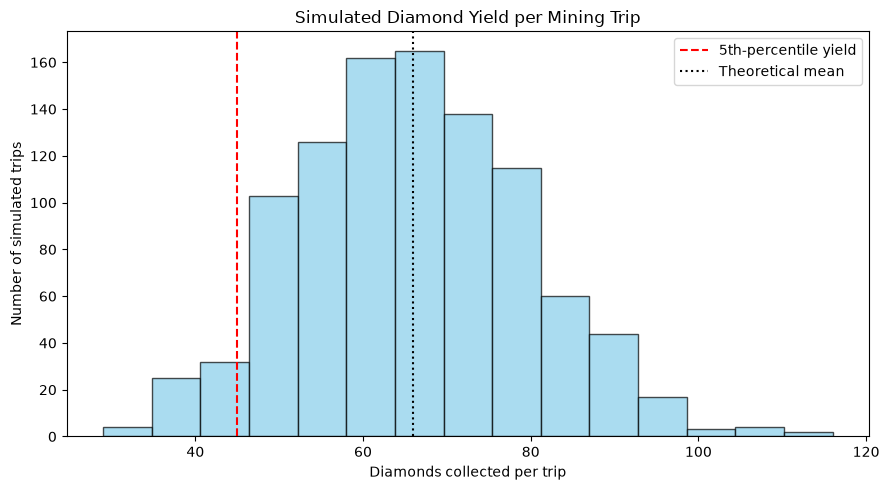

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Model settings
seed = 42
simulations = 1000
mean_ores_per_trip = 30
drop_values = np.array([1, 2, 3, 4])
drop_probabilities = np.array([0.4, 0.2, 0.2, 0.2])

rng = np.random.default_rng(seed)

# Simulate the number of ores mined on each trip
ores_per_trip = rng.poisson(lam=mean_ores_per_trip, size=simulations,)
max_ores = np.max(ores_per_trip)

# Generate potential drops and the ores actually mined
all_drops = rng.choice(drop_values, size=(simulations, max_ores),p=drop_probabilities,)

col_numbers = np.arange(max_ores)
valid_mask = col_numbers < ores_per_trip[:, None]
actual_drops = valid_mask * all_drops

# Total diamond yield for each trip
diamond_stash = np.cumsum(actual_drops, axis=1)
final_totals = diamond_stash[:, -1]

# Summarise the simulated outcomes
lower_yield_threshold = np.percentile(final_totals, 5)
mean_diamonds = np.mean(final_totals)
standard_deviation = np.std(final_totals)

# Compare the simulation with the theoretical expected yield
expected_drop_per_ore = np.sum(drop_values * drop_probabilities)
theoretical_mean = mean_ores_per_trip * expected_drop_per_ore

print(f"Number of simulated trips: {simulations:,}")
print(f"Theoretical mean yield: {theoretical_mean:.2f} diamonds")
print(f"Simulated mean yield: {mean_diamonds:.2f} diamonds")
print(f"Standard deviation: {standard_deviation:.2f} diamonds")
print(f"Estimated 5th-percentile yield: {lower_yield_threshold:.1f} diamonds")

# Plot the distribution of yields
plt.figure(figsize=(9, 5))

plt.hist(
    final_totals,
    bins=15,
    color="skyblue",
    edgecolor="black",
    alpha=0.7,
)

plt.axvline(
    lower_yield_threshold,
    color="red",
    linestyle="--",
    label="5th-percentile yield",
)

plt.axvline(
    theoretical_mean,
    color="black",
    linestyle=":",
    label="Theoretical mean",
)

plt.title("Simulated Diamond Yield per Mining Trip")
plt.xlabel("Diamonds collected per trip")
plt.ylabel("Number of simulated trips")
plt.legend()
plt.tight_layout()
plt.show()

## Findings

Under the model assumptions, the theoretical mean yield is
66 diamonds per trip. The simulated mean provides a check
against this prediction.

The fifth-percentile yield describes the lower end of the
simulated outcomes. It is not the minimum possible yield
or a guarantee about a future trip.

## Limitations

- Ore counts and drop probabilities are illustrative assumptions,
  not validated against actual gameplay.
- The model assumes independent drops and does not include
  travel time, danger or inventory limits.
- Results are estimates from 1,000 simulated trips and may
  change with a different random seed.